# 3D analysis plots

In this notebook, I'll plot these quantities from the 3D simulations: $\beta(r)$, $\gamma(r)$, $\psi(r)$, and $G_\perp (r)$.

# Imports + load simulation data

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size':14})
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib.cm import GnBu, viridis

import sys
sys.path.insert(0, '/projects/b1094/jding/athena/vis/python')
import athena_read
import glob


In [2]:
## Snapshots registration
sim_name = 'disk-planet9'
path = '/scratch/phn2956/' + sim_name + '/'
snapshot_list = sorted(glob.glob(path+'disk.out1.*.athdf'))
# output files containing user-defined output variables (uov)
snapshot_list_uov = sorted(glob.glob(path+'disk.out4.*.athdf'))
print("Number of snapshots:", len(snapshot_list))

alpha = 0.01 # 0.004 # 0.2
cs = 0.05 # 0.05 # 0.1

Number of snapshots: 51


In [5]:
ath_data  = athena_read.athdf(snapshot_list[0],num_ghost=0,quantities=[])

### read in Athena++ domain
rad_app = ath_data['x1v']
theta_app = ath_data['x2v']
phi_app = ath_data['x3v']

rad_3d, theta_3d, phi_3d = np.meshgrid(rad_app, theta_app, phi_app, indexing='ij')

## numerical derivatives

In [14]:
def derivative(f, x):
    '''
    Returns first derivative of f(x) with respect to the domain x.

    '''
    
    # 2nd-order differences is more accurate for, eg, a log radial grid
    return np.gradient(f, x, axis=0, edge_order=2)

def p_derivative(f, x, axis):
    '''
    Returns the first partial derivative of f(R,phi) in the R (axis=0)
    or phi (axis=1) direction. x is the domain over which
    the derivative is taken.

    Assumes that phi is uniformly spaced.

    '''

    assert ((axis == 0 and len(x) == f.shape[0]) or \
            (axis == 1 and len(x) == f.shape[1])) 

    if axis==0:
        # 2nd-order differences is more accurate for a log radial grid
        return np.gradient(f, x, axis=0, edge_order=2)
    else:
        # handle boundaries (phi is periodic)
        dphi = x[1] - x[0]
        return (np.roll(f, -1, axis=1) - np.roll(f, 1, axis=1)) / (2*dphi)


# Inclination profile ($\beta$ and $\gamma$)

Given the total angular momentum vector $\vec{L}(R)$, the tilt $\beta$ and twist $\gamma$ are defined via $\hat{L} = \langle \cos \gamma \sin \beta, \sin \gamma \sin \beta, \cos \beta \rangle$. Here, I calculate $\beta$ by taking the inverse cosine of $\hat{L}_z$. Meanwhile, $\gamma$ comes from taking the inverse cosine of $\hat{L}_x/\sin\beta$ and changing its sign accordingly (depending on the sign of $\hat{L}_y$).

Note that $\sin \beta$ will be positive. (It would only be negative if a ring flipped upside down, which shouldn't happen.)

## helper functions

In [8]:
## helper functions
def SphToCart(r, theta, phi):
    '''
    Given spherical coordinates r, theta, and phi, return the Cartesian
    coordinates x, y, and z.
    
    '''

    x = r * np.sin(theta) * np.cos(phi)
    y = r * np.sin(theta) * np.sin(phi)
    z = r * np.cos(theta)

    return x, y, z

def VelSphToCart(theta, phi, vr, vtheta, vphi):
    '''
    Given spherical coordinates (theta,phi) and the velocity components
    in spherical coordinates, return the velocity components in 
    Cartesian coordinates.

    '''

    rHat = [np.sin(theta)*np.cos(phi), np.sin(theta)*np.sin(phi), np.cos(theta)]
    thetaHat = [np.cos(theta)*np.cos(phi), np.cos(theta)*np.sin(phi), -np.sin(theta)]
    phiHat = [-np.sin(phi), np.cos(phi), 0]

    vx = vr*rHat[0] + vtheta*thetaHat[0] + vphi*phiHat[0]
    vy = vr*rHat[1] + vtheta*thetaHat[1] + vphi*phiHat[1]
    vz = vr*rHat[2] + vtheta*thetaHat[2] + vphi*phiHat[2]

    return vx, vy, vz

def getBetaGamma(rs, thetas, phis, x1f, dens, vrs, vthetas, vphis):
    '''
    Calculates tilt (beta) and twist (gamma) as a function of r.
    
    Takes in the 3D volume-centered coordinate grids (rs, thetas, phis), 
    the face-centered r coordinates (x1f), the 3D density data array, 
    and the (spherical) velocity component data arrays.
    
    '''

    N_theta = dens.shape[1]
    N_phi = dens.shape[2]
    drs = x1f[1:] - x1f[:-1]
    drs = drs[:,None,None] # expand to 3D
    # assumes uniform spacing in angular coords
    dtheta = thetas[0,1,0] - thetas[0,0,0]
    dphi = phis[0,0,1] - phis[0,0,0]

    # Cartesian coordinates
    xs, ys, zs = SphToCart(rs, thetas, phis)
    vxs, vys, vzs = VelSphToCart(thetas, phis, vrs, vthetas, vphis)
    
    dVs = rs*rs * np.sin(thetas) * drs * dtheta * dphi
    Lxs = dens*dVs * (ys*vzs - zs*vys)
    Lys = dens*dVs * (zs*vxs - xs*vzs)
    Lzs = dens*dVs * (xs*vys - ys*vxs)

    # integrate over theta,phi
    Lx_R = np.sum(Lxs[:,:,:],axis=(1,2))
    Ly_R = np.sum(Lys[:,:,:],axis=(1,2))
    Lz_R = np.sum(Lzs[:,:,:],axis=(1,2))

    Lmag = np.sqrt(Lx_R*Lx_R + Ly_R*Ly_R + Lz_R*Lz_R)
    Lz_hats = Lz_R / Lmag
    betas = np.arccos(Lz_hats)

    Lx_hats = Lx_R / Lmag
    Ly_hats = Ly_R / Lmag
    gammas = np.empty_like(betas)
    for i in range(len(gammas)):
        Lx = Lx_hats[i]
        Ly = Ly_hats[i]
        beta = betas[i]
        if (Ly >= 0):
            gammas[i] = np.arccos(Lx / np.sin(beta))
        else:
            gammas[i] = -np.arccos(Lx / np.sin(beta))

    #print("Lz_hats:", Lz_hats)
    return betas, gammas

## plot beta, gamma

/tmp/ipykernel_287541/3561900078.py:79: RuntimeWarning: invalid value encountered in arccos
  gammas[i] = -np.arccos(Lx / np.sin(beta))
/tmp/ipykernel_287541/3561900078.py:77: RuntimeWarning: invalid value encountered in arccos
  gammas[i] = np.arccos(Lx / np.sin(beta))


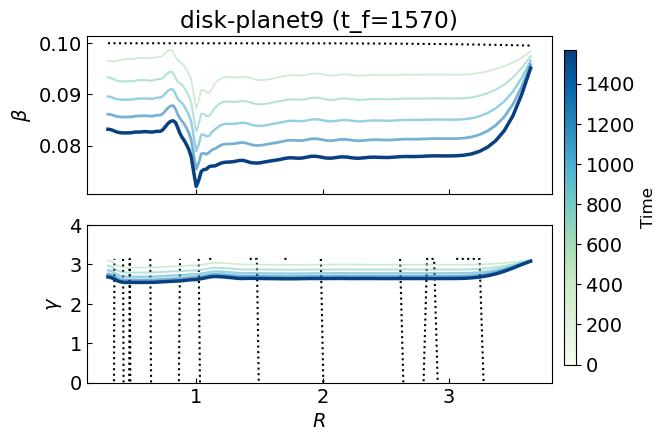

In [13]:
snapshot_plot = snapshot_list[0:51:10] # snapshot_list[0:101:5]

norm   = mcolors.PowerNorm(gamma=1.5, vmin=0, vmax=len(snapshot_plot)-1)
colors = [GnBu(0.3 + 0.7 * norm(i)) for i in range(len(snapshot_plot))]

fig,axs = plt.subplots(2,1, figsize=(6,4.5),sharex=True,sharey=False)

for i, frame in enumerate(snapshot_plot):
    ## read in primitive fields
    ath_data  = athena_read.athdf(frame,num_ghost=0,quantities=["rho", "vel1", "vel2", "vel3"])
    t_sim = ath_data['Time']

    vx1 = np.swapaxes(ath_data['vel1'],0,2) # index convention: (r, theta, phi)
    vx2 = np.swapaxes(ath_data['vel2'],0,2)
    vx3 = np.swapaxes(ath_data['vel3'],0,2)
    den = np.swapaxes(ath_data['rho'],0,2)

    ## get beta, gamma arrays
    x1f = ath_data['x1f'] # face-centered r coordinates
    betas, gammas = getBetaGamma(rad_3d, theta_3d, phi_3d, x1f, den, vx1, vx2, vx3)
    
    ## plotting
    current_color = colors[i]
    lw     = 1.0 + 1.5 * (i / len(snapshot_plot))
    zorder = i + 10 
    
    if t_sim== 0:
        kws = {'color': 'k', 'ls':':','lw': 1.5, 'label': r'initial' % t_sim, 'zorder': zorder}
    elif i == len(snapshot_plot) - 1:
        kws = {'color': '#084081', 'lw': 2.5, 'label': r'final' % t_sim, 'zorder': zorder + 100}
    else:
        kws = {'color': current_color, 'lw': lw, 'alpha': 0.6, 'zorder': zorder}
        
    axs[0].plot(rad_app,betas,**kws)
    axs[1].plot(rad_app,gammas,**kws)
    
sm = plt.cm.ScalarMappable(cmap=GnBu, norm=plt.Normalize(vmin=0, vmax=t_sim))
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7]) # [left, bottom, width, height]
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('Time', fontsize=12)

#### labels
axs[0].set_ylabel(r'$\beta$')
axs[1].set_ylabel(r'$\gamma$')
axs[1].set_xlabel(r'$R$')
#axs.set_xlim(rad_app[[0,-1]])
axs[1].set_ylim(0., 4.)

axs[0].set_title(sim_name + " (t_f=%.0f)"%t_sim)

for ax in axs.flatten():
    ax.tick_params(which='both',direction='in')

save_fig = False
if save_fig:
    plt.savefig("Figs/beta_gamma_profiles/" + sim_name + "-beta.png", bbox_inches='tight')


# Warp profile ($\psi$)

In [24]:
def getPsi(rs, thetas, phis, x1f, dens, vrs, vthetas, vphis):
    '''
    Calculates warp (psi) as a function of r.
    
    Takes in the 3D volume-centered coordinate grids (rs, thetas, phis), 
    the face-centered r coordinates (x1f), the 3D density data array, 
    and the (spherical) velocity component data arrays.
    
    '''

    N_theta = dens.shape[1]
    N_phi = dens.shape[2]
    drs = x1f[1:] - x1f[:-1]
    drs = drs[:,None,None] # expand to 3D
    # assumes uniform spacing in angular coords
    dtheta = thetas[0,1,0] - thetas[0,0,0]
    dphi = phis[0,0,1] - phis[0,0,0]

    # Cartesian coordinates
    xs, ys, zs = SphToCart(rs, thetas, phis)
    vxs, vys, vzs = VelSphToCart(thetas, phis, vrs, vthetas, vphis)
    
    dVs = rs*rs * np.sin(thetas) * drs * dtheta * dphi
    Lxs = dens*dVs * (ys*vzs - zs*vys)
    Lys = dens*dVs * (zs*vxs - xs*vzs)
    Lzs = dens*dVs * (xs*vys - ys*vxs)

    # integrate over theta,phi
    Lx_R = np.sum(Lxs[:,:,:],axis=(1,2))
    Ly_R = np.sum(Lys[:,:,:],axis=(1,2))
    Lz_R = np.sum(Lzs[:,:,:],axis=(1,2))

    Lmag = np.sqrt(Lx_R*Lx_R + Ly_R*Ly_R + Lz_R*Lz_R)
    Lx_hat = Lx_R / Lmag
    Ly_hat = Ly_R / Lmag
    Lz_hat = Lz_R / Lmag                   

    psi_x = rad_app * derivative(Lx_hat, rad_app)
    psi_y = rad_app * derivative(Ly_hat, rad_app)
    psi_z = rad_app * derivative(Lz_hat, rad_app)

    # return the magnitude of psi
    psis = np.sqrt(psi_x*psi_x + psi_y*psi_y + psi_z*psi_z)
    #return psi_x, psi_y, psi_z
    return psis

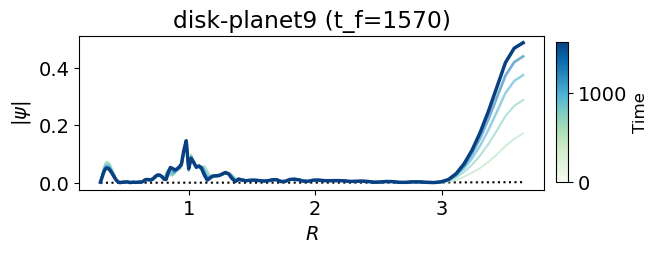

In [25]:
snapshot_plot = snapshot_list[0:51:10] # snapshot_list[0:101:5]

norm   = mcolors.PowerNorm(gamma=1.5, vmin=0, vmax=len(snapshot_plot)-1)
colors = [GnBu(0.3 + 0.7 * norm(i)) for i in range(len(snapshot_plot))]

fig,axs = plt.subplots(1,1, figsize=(6,2),sharex=True,sharey=False)

for i, frame in enumerate(snapshot_plot):
    ## read in primitive fields
    ath_data  = athena_read.athdf(frame,num_ghost=0,quantities=["rho", "vel1", "vel2", "vel3"])
    t_sim = ath_data['Time']

    vx1 = np.swapaxes(ath_data['vel1'],0,2) # index convention: (r, theta, phi)
    vx2 = np.swapaxes(ath_data['vel2'],0,2)
    vx3 = np.swapaxes(ath_data['vel3'],0,2)
    den = np.swapaxes(ath_data['rho'],0,2)

    ## get beta, gamma arrays
    x1f = ath_data['x1f'] # face-centered r coordinates
    psis = getPsi(rad_3d, theta_3d, phi_3d, x1f, den, vx1, vx2, vx3)
    #psi_x,psi_y,psi_z = getPsi(rad_3d, theta_3d, phi_3d, x1f, den, vx1, vx2, vx3)

    
    ## plotting
    current_color = colors[i]
    lw     = 1.0 + 1.5 * (i / len(snapshot_plot))
    zorder = i + 10 
    
    if t_sim== 0:
        kws = {'color': 'k', 'ls':':','lw': 1.5, 'label': r'initial' % t_sim, 'zorder': zorder}
    elif i == len(snapshot_plot) - 1:
        kws = {'color': '#084081', 'lw': 2.5, 'label': r'final' % t_sim, 'zorder': zorder + 100}
    else:
        kws = {'color': current_color, 'lw': lw, 'alpha': 0.6, 'zorder': zorder}

    axs.plot(rad_app,psis,**kws)
    
    
sm = plt.cm.ScalarMappable(cmap=GnBu, norm=plt.Normalize(vmin=0, vmax=t_sim))
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7]) # [left, bottom, width, height]
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('Time', fontsize=12)

#### labels
axs.set_ylabel(r'$|\psi|$')
axs.set_xlabel(r'$R$')
#axs.set_xlim(rad_app[[0,-1]])
#axs[1].set_ylim(0., 4.)

axs.set_title(sim_name + " (t_f=%.0f)"%t_sim)

# for ax in axs.flatten():
#     ax.tick_params(which='both',direction='in')

save_fig = False
if save_fig:
    plt.savefig("Figs/warp_profiles/" + sim_name + "-beta.png", bbox_inches='tight')


# Torque profile ($\mathcal{G}_\perp$)

The part of a vector $\vec{G}$ perpendicular to $\hat \ell $ is $\vec{G}_\perp = \vec{G} - (\vec{G} \cdot \hat\ell) \hat \ell$.

In [30]:
def getGperp(rs, thetas, phis, x1f, dens, vrs, vthetas, vphis):
    '''
    Calculates the internal torque (G_perp) as a function of r.
    
    Takes in the 3D volume-centered coordinate grids (rs, thetas, phis), 
    the face-centered r coordinates (x1f), the 3D density data array, 
    and the (spherical) velocity component data arrays.
    
    '''

    N_theta = dens.shape[1]
    N_phi = dens.shape[2]
    drs = x1f[1:] - x1f[:-1]
    drs = drs[:,None,None] # expand to 3D
    # assumes uniform spacing in angular coords
    dtheta = thetas[0,1,0] - thetas[0,0,0]
    dphi = phis[0,0,1] - phis[0,0,0]

    # Cartesian coordinates
    xs, ys, zs = SphToCart(rs, thetas, phis)
    vxs, vys, vzs = VelSphToCart(thetas, phis, vrs, vthetas, vphis)

    dOmegas = rs*rs * np.sin(thetas) * dtheta * dphi
    dVs = drs * dOmegas
    
    ## step 1: calculate G
    Gxs = dens*vrs * (ys*vzs - zs*vys) * dOmegas
    Gys = dens*vrs * (zs*vxs - xs*vzs) * dOmegas
    Gzs = dens*vrs * (xs*vys - ys*vxs) * dOmegas
    # integrate over theta,phi
    Gx_R = np.sum(Gxs[:,:,:],axis=(1,2))
    Gy_R = np.sum(Gys[:,:,:],axis=(1,2))
    Gz_R = np.sum(Gzs[:,:,:],axis=(1,2))

    ## step 2: calculate component perpendicular to lhat
    # compute Lhat
    Lxs = dens*dVs * (ys*vzs - zs*vys)
    Lys = dens*dVs * (zs*vxs - xs*vzs)
    Lzs = dens*dVs * (xs*vys - ys*vxs)
    # integrate over theta,phi
    Lx_R = np.sum(Lxs[:,:,:],axis=(1,2))
    Ly_R = np.sum(Lys[:,:,:],axis=(1,2))
    Lz_R = np.sum(Lzs[:,:,:],axis=(1,2))
    Lmag = np.sqrt(Lx_R*Lx_R + Ly_R*Ly_R + Lz_R*Lz_R)
    Lx_hat = Lx_R / Lmag
    Ly_hat = Ly_R / Lmag
    Lz_hat = Lz_R / Lmag  

    # \vecG \dot \hat\ell is an (N_R,) array
    GdotElls = Gx_R*Lx_hat + Gy_R*Ly_hat + Gz_R*Lz_hat
    # the torque vector at each r is stored in an (N_r,3) array
    Gs = np.zeros(shape=(len(rad_app),3))
    Gparas = np.zeros(shape=(len(rad_app),3))

    Gs[:,0] = Gx_R
    Gs[:,1] = Gy_R
    Gs[:,2] = Gz_R
    Gparas[:,0] = GdotElls * Lx_hat
    Gparas[:,1] = GdotElls * Ly_hat
    Gparas[:,2] = GdotElls * Lz_hat

    Gperps = Gs - Gparas
    return Gperps

## plot G

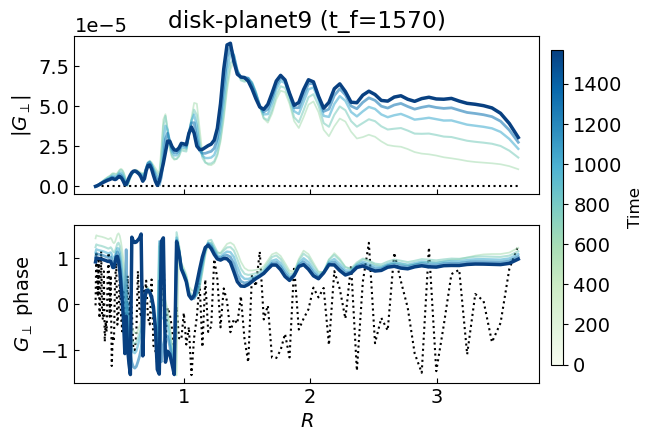

In [33]:
snapshot_plot = snapshot_list[0:51:10] # snapshot_list[0:101:5]

norm   = mcolors.PowerNorm(gamma=1.5, vmin=0, vmax=len(snapshot_plot)-1)
colors = [GnBu(0.3 + 0.7 * norm(i)) for i in range(len(snapshot_plot))]

fig,axs = plt.subplots(2,1, figsize=(6,4.5),sharex=True,sharey=False)

for i, frame in enumerate(snapshot_plot):
    ## read in primitive fields
    ath_data  = athena_read.athdf(frame,num_ghost=0,quantities=["rho", "vel1", "vel2", "vel3"])
    t_sim = ath_data['Time']

    vx1 = np.swapaxes(ath_data['vel1'],0,2) # index convention: (r, theta, phi)
    vx2 = np.swapaxes(ath_data['vel2'],0,2)
    vx3 = np.swapaxes(ath_data['vel3'],0,2)
    den = np.swapaxes(ath_data['rho'],0,2)

    ## get beta, gamma arrays
    x1f = ath_data['x1f'] # face-centered r coordinates
    Gperps = getGperp(rad_3d, theta_3d, phi_3d, x1f, den, vx1, vx2, vx3)
    Gperp_mag = np.linalg.norm(Gperps, axis=1)
    Gperp_phase = np.arctan(Gperps[:,1]/Gperps[:,0])
    
    ## plotting
    current_color = colors[i]
    lw     = 1.0 + 1.5 * (i / len(snapshot_plot))
    zorder = i + 10 
    
    if t_sim== 0:
        kws = {'color': 'k', 'ls':':','lw': 1.5, 'label': r'initial' % t_sim, 'zorder': zorder}
    elif i == len(snapshot_plot) - 1:
        kws = {'color': '#084081', 'lw': 2.5, 'label': r'final' % t_sim, 'zorder': zorder + 100}
    else:
        kws = {'color': current_color, 'lw': lw, 'alpha': 0.6, 'zorder': zorder}
        
    axs[0].plot(rad_app, Gperp_mag, **kws)
    axs[1].plot(rad_app, Gperp_phase, **kws)
    
sm = plt.cm.ScalarMappable(cmap=GnBu, norm=plt.Normalize(vmin=0, vmax=t_sim))
cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7]) # [left, bottom, width, height]
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('Time', fontsize=12)

#### labels
axs[0].set_ylabel(r'$|G_\perp|$')
axs[1].set_ylabel(r'$G_\perp$ phase')
axs[1].set_xlabel(r'$R$')
#axs.set_xlim(rad_app[[0,-1]])
#axs[1].set_ylim(0., 4.)

axs[0].set_title(sim_name + " (t_f=%.0f)"%t_sim)

for ax in axs.flatten():
    ax.tick_params(which='both',direction='in')

save_fig = False
if save_fig:
    plt.savefig("Figs/Gperp_profiles/" + sim_name + "-beta.png", bbox_inches='tight')
